# Modelling the racing line through Turn 13, Jeddah Corniche Circuit

**Research question:** To what extent can parametric curves and bi-arc interpolation be used to mathematically model and analyse the optimal racing line through Turn 13 of the Jeddah Corniche Circuit?

This notebook:

1. Models the track edges (inner and outer) and two racing lines (**theoretical** and **traditional**) with parametric cubic splines $x(t),\ y(t)$.
2. Writes out the piecewise spline equations.
3. Uses differential calculus to find the **curvature** $\kappa$ along each racing line.
4. Links curvature to **lateral (centripetal) acceleration** and the **maximum cornering speed**.
5. Approximates each racing line with a **bi-arc** (two tangent-continuous circular arcs) and compares it to the spline model.
6. Uses the braking equation $v^2 = v_0^2 + 2As$ to estimate the time through the corner on each line.
7. Shows the Bézier reconstruction of the lines and draws the model over the aerial image of the corner.

Coordinates are in grid units read off the aerial image of Turn 13 (see the last section).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.interpolate import CubicSpline, splprep, splev
from scipy.integrate import cumulative_trapezoid

plt.rcParams["figure.dpi"] = 110

## 1. Data points

Points picked along each line on the aerial image of Turn 13 (grid units).

In [ ]:
# Inner edge of the track (apex side)
inner = np.array([
    (0.00, 1.40), (1.00, 1.65), (2.00, 2.08), (3.00, 2.78), (4.00, 3.90),
    (4.60, 5.00), (5.00, 6.50), (5.00, 7.50), (4.95, 8.00), (4.70, 9.00),
    (4.25, 10.00), (3.60, 11.00), (2.30, 12.00), (-0.20, 13.00), (-2.00, 13.30),
])

# Outer edge of the track
outer = np.array([
    (0.00, 0.00), (1.00, 0.22), (2.00, 0.52), (3.00, 1.03), (4.00, 1.76),
    (5.00, 2.86), (5.40, 3.40), (6.00, 4.62), (6.38, 6.00), (6.50, 7.00),
    (6.45, 8.00), (6.28, 9.00), (5.95, 10.00), (5.38, 11.07), (4.67, 12.00),
    (3.53, 13.00), (1.50, 14.00), (-2.00, 14.80), (-3.00, 14.82),
])

# Theoretical racing line
theoretical = np.array([
    (0.00, 0.00), (1.00, 0.50), (2.00, 1.00), (3.00, 2.00), (3.50, 2.50),
    (4.00, 3.20), (5.00, 4.90), (5.30, 6.00), (5.30, 8.00), (5.30, 9.50),
    (5.10, 10.50), (4.93, 11.07), (4.58, 11.50), (4.20, 12.00), (3.60, 12.60),
    (3.00, 12.80), (2.40, 13.00), (0.50, 13.50), (-1.00, 14.00),
])

# Traditional racing line (outside - inside - outside)
traditional = np.array([
    (-1.00, 0.00), (0.00, 1.00), (1.00, 1.50), (2.00, 2.00), (3.00, 2.78),
    (4.00, 3.50), (4.88, 5.07), (5.18, 7.00), (5.08, 9.00), (4.58, 10.00),
    (4.00, 11.00), (3.00, 12.00), (2.50, 12.50), (2.00, 13.00), (1.00, 14.00),
])

lines = {"Inner": inner, "Outer": outer, "Theoretical": theoretical, "Traditional": traditional}
for name, pts in lines.items():
    print(f"{name:12s} {len(pts):2d} points")

Inner        15 points
Outer        19 points
Theoretical  19 points
Traditional  15 points


## 2. Parametric cubic splines

Each line is modelled as a parametric curve $\big(x(t),\ y(t)\big)$, where $t = 0, 1, 2, \dots$ is the index of the data point.
$x(t)$ and $y(t)$ are each a piecewise cubic

$$S_i(t) = a_i + b_i\,(t-i) + c_i\,(t-i)^2 + d_i\,(t-i)^3, \qquad i \le t \le i+1,$$

joined so that the value, first derivative and second derivative are continuous at every point.

In [3]:
def parametric_spline(points):
    # Fit x(t) and y(t) with t = 0, 1, 2, ... (one unit per data point)
    t = np.arange(len(points))
    return CubicSpline(t, points[:, 0]), CubicSpline(t, points[:, 1]), t

splines = {name: parametric_spline(pts) for name, pts in lines.items()}

def sample(name, n=600):
    sx, sy, t = splines[name]
    tt = np.linspace(t[0], t[-1], n)
    return tt, sx(tt), sy(tt)

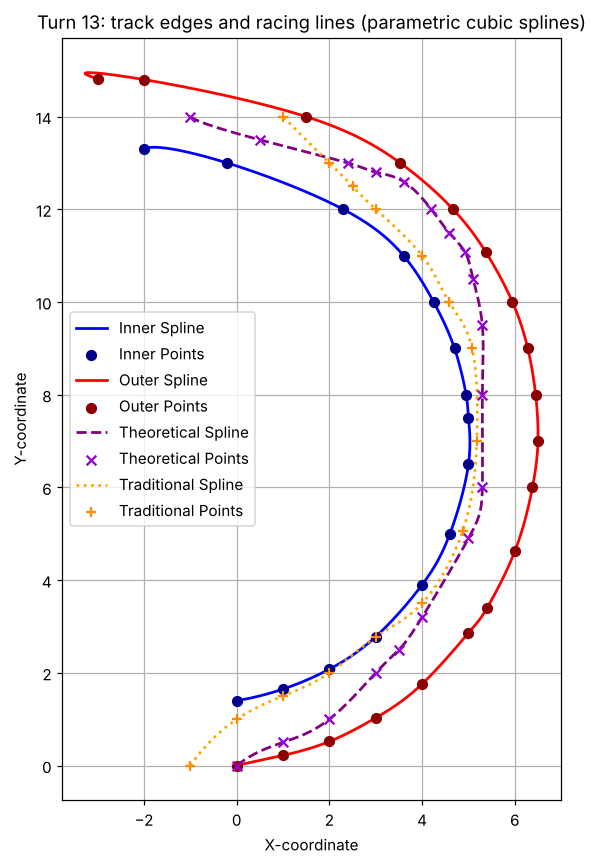

In [4]:
style = {
    "Inner":       dict(color="blue",       ls="-",  marker="o", mc="darkblue"),
    "Outer":       dict(color="red",        ls="-",  marker="o", mc="darkred"),
    "Theoretical": dict(color="purple",     ls="--", marker="x", mc="darkviolet"),
    "Traditional": dict(color="orange",     ls=":",  marker="+", mc="darkorange"),
}

fig, ax = plt.subplots(figsize=(7, 9))
for name, pts in lines.items():
    s = style[name]
    _, x, y = sample(name)
    ax.plot(x, y, color=s["color"], ls=s["ls"], lw=1.8, label=f"{name} Spline")
    ax.scatter(pts[:, 0], pts[:, 1], color=s["mc"], marker=s["marker"], s=40, zorder=5, label=f"{name} Points")
ax.set_xlabel("X-coordinate")
ax.set_ylabel("Y-coordinate")
ax.set_title("Turn 13: track edges and racing lines (parametric cubic splines)")
ax.set_aspect("equal")
ax.grid(True)
ax.legend(loc="center left")
plt.show()

## 3. Piecewise spline equations

Writing out $Y(t)$ for the inner edge. Each row is one cubic piece $S_i(t)$.

In [5]:
def piecewise_table(spline):
    # Coefficients a (value), b, c, d for each piece, i <= t <= i+1
    d, c, b, a = spline.c   # scipy stores highest power first
    return pd.DataFrame({"interval": [f"{i} ≤ t ≤ {i+1}" for i in range(len(a))],
                         "a": a, "b": b, "c": c, "d": d}).round(6)

def print_piecewise(spline, label):
    d, c, b, a = spline.c
    print(f"{label} =")
    for i in range(len(a)):
        print(f"   {a[i]:.6g} + {b[i]:.6f}(t-{i}) + {c[i]:.6f}(t-{i})^2 + {d[i]:.6f}(t-{i})^3,   {i} ≤ t ≤ {i+1}")

sx_in, sy_in, _ = splines["Inner"]
print_piecewise(sy_in, "Inner Y(t)")
piecewise_table(sy_in)

Inner Y(t) =
   1.4 + 0.162501(t-0) + 0.086248(t-0)^2 + 0.001251(t-0)^3,   0 ≤ t ≤ 1
   1.65 + 0.338749(t-1) + 0.090000(t-1)^2 + 0.001251(t-1)^3,   1 ≤ t ≤ 2
   2.08 + 0.522501(t-2) + 0.093752(t-2)^2 + 0.083747(t-2)^3,   2 ≤ t ≤ 3
   2.78 + 0.961246(t-3) + 0.344993(t-3)^2 + -0.186239(t-3)^3,   3 ≤ t ≤ 4
   3.9 + 1.092515(t-4) + -0.213724(t-4)^2 + 0.221209(t-4)^3,   4 ≤ t ≤ 5
   5 + 1.328694(t-5) + 0.449904(t-5)^2 + -0.278598(t-5)^3,   5 ≤ t ≤ 6
   6.5 + 1.392707(t-6) + -0.385891(t-6)^2 + -0.006816(t-6)^3,   6 ≤ t ≤ 7
   7.5 + 0.600476(t-7) + -0.406340(t-7)^2 + 0.305863(t-7)^3,   7 ≤ t ≤ 8
   8 + 0.705387(t-8) + 0.511250(t-8)^2 + -0.216637(t-8)^3,   8 ≤ t ≤ 9
   9 + 1.077976(t-9) + -0.138660(t-9)^2 + 0.060684(t-9)^3,   9 ≤ t ≤ 10
   10 + 0.982707(t-10) + 0.043391(t-10)^2 + -0.026098(t-10)^3,   10 ≤ t ≤ 11
   11 + 0.991194(t-11) + -0.034904(t-11)^2 + 0.043710(t-11)^3,   11 ≤ t ≤ 12
   12 + 1.052516(t-12) + 0.096226(t-12)^2 + -0.148742(t-12)^3,   12 ≤ t ≤ 13
   13 + 0.798742(t-13) + -0.35

,interval,a,b,c,d
0,0 ≤ t ≤ 1,1.40,0.162501,0.086248,0.001251
1,1 ≤ t ≤ 2,1.65,0.338749,0.090000,0.001251
2,2 ≤ t ≤ 3,2.08,0.522501,0.093752,0.083747
3,3 ≤ t ≤ 4,2.78,0.961246,0.344993,-0.186239
4,4 ≤ t ≤ 5,3.90,1.092515,-0.213724,0.221209
5,5 ≤ t ≤ 6,5.00,1.328694,0.449904,-0.278598
6,6 ≤ t ≤ 7,6.50,1.392707,-0.385891,-0.006816
7,7 ≤ t ≤ 8,7.50,0.600476,-0.406340,0.305863
8,8 ≤ t ≤ 9,8.00,0.705387,0.511250,-0.216637
9,9 ≤ t ≤ 10,9.00,1.077976,-0.138660,0.060684


## 4. Curvature

For a parametric curve, the curvature is

$$\kappa = \frac{\left| x'\,y'' - y'\,x'' \right|}{\left( x'^2 + y'^2 \right)^{3/2}}$$

and the radius of curvature is $r = 1/\kappa$. A larger curvature means a tighter turn.

**Reparametrisation.** The splines above use the point number $t$ as the parameter. Since the points are not evenly spaced, the "speed" $\sqrt{x'^2+y'^2}$ of the parametrisation jumps around, and small errors in reading the points off the image turn into large spikes in $\kappa$ (see the faint lines in the plot).
For the curvature analysis the lines are therefore reparametrised by **distance along the line** (chord length),

$$s = \int \sqrt{x'(t)^2 + y'(t)^2}\; dt ,$$

and fitted with a lightly *smoothing* spline. The smoothing allows each fitted line to miss the points by about $\sigma = 0.1$ grid units (≈ 1 m), roughly the accuracy of picking points by hand.

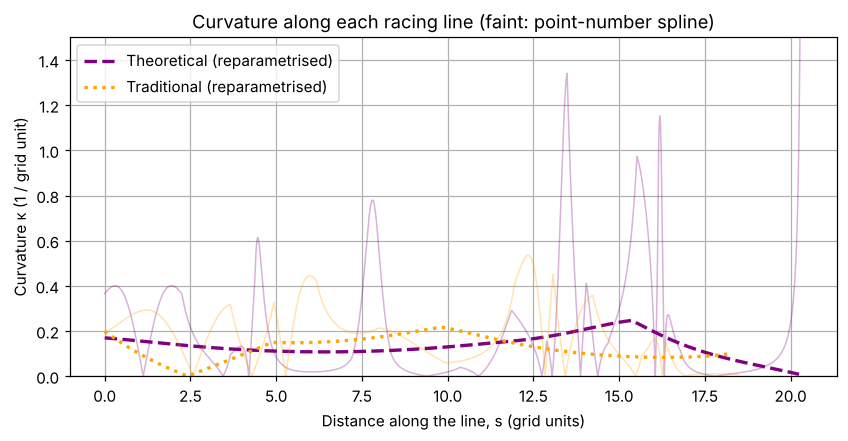

Theoretical  length = 20.24   max κ = 0.247 at (3.56, 12.48)   min radius = 4.05 grid units
Traditional  length = 18.29   max κ = 0.218 at (5.29, 6.99)   min radius = 4.60 grid units


In [6]:
SIGMA = 0.1   # assumed accuracy of the hand-picked points (grid units)

def smooth_profile(points, sigma=SIGMA, n=2000):
    # Chord-length parametrisation + smoothing cubic spline
    chord = np.r_[0, np.cumsum(np.hypot(*np.diff(points, axis=0).T))]
    tck, _ = splprep([points[:, 0], points[:, 1]], u=chord / chord[-1], s=len(points) * sigma**2, k=3)
    u = np.linspace(0, 1, n)
    x, y = splev(u, tck)
    dx, dy = splev(u, tck, der=1)
    ddx, ddy = splev(u, tck, der=2)
    speed = np.hypot(dx, dy)
    kappa = np.abs(dx * ddy - dy * ddx) / speed**3
    s = cumulative_trapezoid(speed, u, initial=0)   # distance along the line
    return u, s, kappa, np.asarray(x), np.asarray(y)

def raw_profile(name, n=2000):
    # Curvature straight from the point-number spline (for comparison)
    sx, sy, t = splines[name]
    tt = np.linspace(t[0], t[-1], n)
    dx, dy, ddx, ddy = sx(tt, 1), sy(tt, 1), sx(tt, 2), sy(tt, 2)
    speed = np.hypot(dx, dy)
    return cumulative_trapezoid(speed, tt, initial=0), np.abs(dx * ddy - dy * ddx) / speed**3

profiles = {name: smooth_profile(lines[name]) for name in ["Theoretical", "Traditional"]}

fig, ax = plt.subplots(figsize=(9, 4))
for name, (u, s, k, x, y) in profiles.items():
    s_raw, k_raw = raw_profile(name)
    ax.plot(s_raw, k_raw, color=style[name]["color"], lw=1, alpha=0.3)
    ax.plot(s, k, color=style[name]["color"], ls=style[name]["ls"], lw=2.2, label=f"{name} (reparametrised)")
ax.set_ylim(0, 1.5)
ax.set_xlabel("Distance along the line, s (grid units)")
ax.set_ylabel("Curvature κ (1 / grid unit)")
ax.set_title("Curvature along each racing line (faint: point-number spline)")
ax.grid(True)
ax.legend()
plt.show()

for name, (u, s, k, x, y) in profiles.items():
    i = np.argmax(k)
    print(f"{name:12s} length = {s[-1]:5.2f}   max κ = {k[i]:.3f} at ({x[i]:.2f}, {y[i]:.2f})   min radius = {1/k[i]:.2f} grid units")

## 5. Curvature, lateral acceleration and maximum cornering speed

A car moving at speed $v$ along a path with radius $r$ needs a centripetal (lateral) acceleration

$$a_{lat} = \frac{v^2}{r} = v^2 \kappa .$$

The tyres (and downforce) can only provide up to a maximum $a_{max}$, so the fastest speed at any point is

$$v_{max} = \sqrt{\frac{a_{max}}{\kappa}} = \sqrt{a_{max}\, r} .$$

**Assumptions:** these values set the scale. Change them to test other cases.
`METERS_PER_UNIT` converts grid units to metres, and `A_LAT_MAX` is the lateral grip limit.
Because $v_{max} \propto \sqrt{\text{scale}}$, the *ratio* between the two lines does not depend on these choices.

Theoretical  min radius =   40.5 m   max cornering speed at the tightest point =  39.9 m/s (143.5 km/h)
Traditional  min radius =   46.0 m   max cornering speed at the tightest point =  42.5 m/s (152.9 km/h)


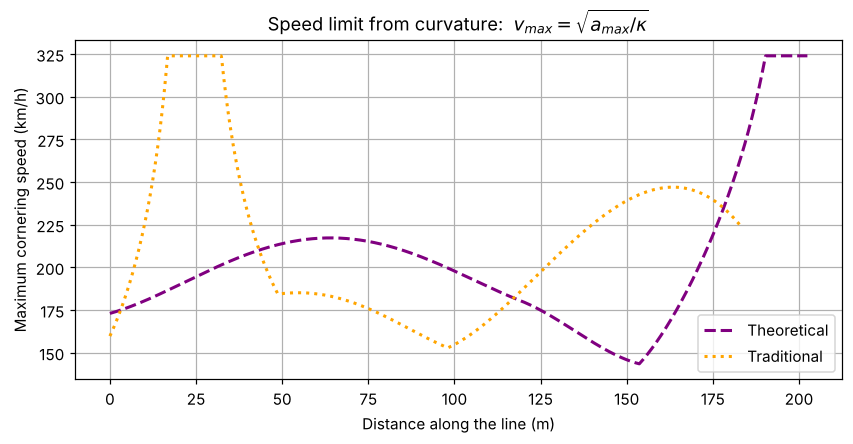

In [7]:
G = 9.81
METERS_PER_UNIT = 10.0      # assumption: about 1.5 grid units across the track ≈ 15 m track width
A_LAT_MAX = 4.0 * G         # assumption: maximum lateral acceleration of the car (m/s^2)
V_TOP = 90.0                # assumption: top speed cap (m/s) ≈ 324 km/h

fig, ax = plt.subplots(figsize=(9, 4))
for name, (u, s, k, x, y) in profiles.items():
    k_m = k / METERS_PER_UNIT                    # curvature in 1/m
    v_lim = np.minimum(np.sqrt(A_LAT_MAX / k_m), V_TOP)
    ax.plot(s * METERS_PER_UNIT, v_lim * 3.6, color=style[name]["color"], ls=style[name]["ls"], lw=2, label=name)
    r_min = 1 / k_m.max()
    print(f"{name:12s} min radius = {r_min:6.1f} m   max cornering speed at the tightest point = "
          f"{np.sqrt(A_LAT_MAX * r_min):5.1f} m/s ({np.sqrt(A_LAT_MAX * r_min) * 3.6:5.1f} km/h)")
ax.set_xlabel("Distance along the line (m)")
ax.set_ylabel("Maximum cornering speed (km/h)")
ax.set_title(r"Speed limit from curvature:  $v_{max}=\sqrt{a_{max}/\kappa}$")
ax.grid(True)
ax.legend()
plt.show()

## 6. Bi-arc model

A bi-arc is two circular arcs joined so that the **tangent direction is continuous** where they meet (G¹ continuity).
It is fitted to the corner itself, from where each line crosses $y = 2$ (entry) to where it crosses $y = 13$ (exit).

Given the entry point $P_0$ with unit tangent $\mathbf{T}_0$ and the exit point $P_1$ with unit tangent $\mathbf{T}_1$, choose distances $d_1, d_2$ and points

$$Q_1 = P_0 + d_1\mathbf{T}_0, \qquad Q_2 = P_1 - d_2\mathbf{T}_1 .$$

The arcs join with a continuous tangent when $|Q_2 - Q_1| = d_1 + d_2$. Squaring this with $\mathbf{v} = P_1 - P_0$ gives

$$d_2 = \frac{\mathbf{v}\cdot\mathbf{v} - 2d_1\,\mathbf{v}\cdot\mathbf{T}_0}{2\,\mathbf{v}\cdot\mathbf{T}_1 + 2d_1\,(1 - \mathbf{T}_0\cdot\mathbf{T}_1)} ,$$

and the junction is $J = \dfrac{d_2 Q_1 + d_1 Q_2}{d_1 + d_2}$. Each arc is the circle tangent to $\mathbf{T}_0$ at $P_0$ (or to $\mathbf{T}_1$ at $P_1$) that passes through $J$; its centre lies on the normal, at signed distance $r = \dfrac{|J-P|^2}{2\,\mathbf{n}\cdot(J-P)}$.

Every $d_1 > 0$ gives a valid bi-arc, so $d_1$ is chosen to make the bi-arc as close as possible to the racing line, with both radii at least 2 grid units (20 m) so the fit cannot use an unrealistically tiny arc.

In [8]:
def perp(v):
    return np.array([-v[1], v[0]])

def arc_through(P, T, J):
    # Circle tangent to unit vector T at P and passing through J
    n = perp(T)
    w = J - P
    signed_r = (w @ w) / (2 * (n @ w))
    return P + signed_r * n, abs(signed_r)

def arc_points(centre, r, A, B, T_at_A, n=200):
    # Points on the circle from A to B, setting off in the direction T_at_A
    a0 = np.arctan2(*(A - centre)[::-1])
    a1 = np.arctan2(*(B - centre)[::-1])
    rA = A - centre
    turn_ccw = (rA[0] * T_at_A[1] - rA[1] * T_at_A[0]) > 0   # 2D cross product
    if turn_ccw and a1 < a0: a1 += 2 * np.pi
    if not turn_ccw and a1 > a0: a1 -= 2 * np.pi
    ang = np.linspace(a0, a1, n)
    return np.column_stack([centre[0] + r * np.cos(ang), centre[1] + r * np.sin(ang)])

def biarc(P0, T0, P1, T1, d1):
    v = P1 - P0
    den = 2 * (v @ T1) + 2 * d1 * (1 - T0 @ T1)
    if abs(den) < 1e-12:
        return None
    d2 = (v @ v - 2 * d1 * (v @ T0)) / den
    if d2 <= 0:
        return None
    Q1, Q2 = P0 + d1 * T0, P1 - d2 * T1
    J = (d2 * Q1 + d1 * Q2) / (d1 + d2)
    c1, r1 = arc_through(P0, T0, J)
    c2, r2 = arc_through(P1, -T1, J)
    pts = np.vstack([arc_points(c1, r1, P0, J, T0), arc_points(c2, r2, P1, J, -T1)[::-1]])
    return dict(P0=P0, P1=P1, T0=T0, T1=T1, J=J, c1=c1, r1=r1, c2=c2, r2=r2, d1=d1, d2=d2, pts=pts)

def corner_section(name, y_entry=2.0, y_exit=13.0):
    u, s, k, x, y = profiles[name]
    i0 = np.argmax(y >= y_entry)
    i1 = len(y) - 1 - np.argmax(y[::-1] <= y_exit)
    return np.column_stack([x[i0:i1 + 1], y[i0:i1 + 1]])

def max_gap(curve, pts):
    # Largest distance from the racing line to the bi-arc
    return np.sqrt(((curve[:, None, :] - pts[None, ::4, :])**2).sum(-1)).min(axis=1).max()

def best_biarc(name, r_min=2.0):
    curve = corner_section(name)
    P0, P1 = curve[0], curve[-1]
    T0 = curve[1] - curve[0];   T0 /= np.linalg.norm(T0)
    T1 = curve[-1] - curve[-2]; T1 /= np.linalg.norm(T1)
    best = None
    for d1 in np.linspace(0.05, 30, 1500):
        B = biarc(P0, T0, P1, T1, d1)
        if B is None or min(B["r1"], B["r2"]) < r_min:
            continue
        gap = max_gap(curve, B["pts"])
        if best is None or gap < best["gap"]:
            best = dict(B, gap=gap, curve=curve)
    return best

biarcs = {name: best_biarc(name) for name in ["Theoretical", "Traditional"]}
for name, B in biarcs.items():
    print(f"{name:12s} d1 = {B['d1']:.2f}, d2 = {B['d2']:.2f}, J = ({B['J'][0]:.2f}, {B['J'][1]:.2f}), "
          f"r1 = {B['r1']:.2f}, r2 = {B['r2']:.2f} grid units")

Theoretical  d1 = 4.23, d2 = 2.63, J = (5.43, 9.27), r1 = 8.87, r2 = 4.84 grid units
Traditional  d1 = 9.80, d2 = 0.14, J = (2.33, 12.83), r1 = 6.50, r2 = 2.53 grid units


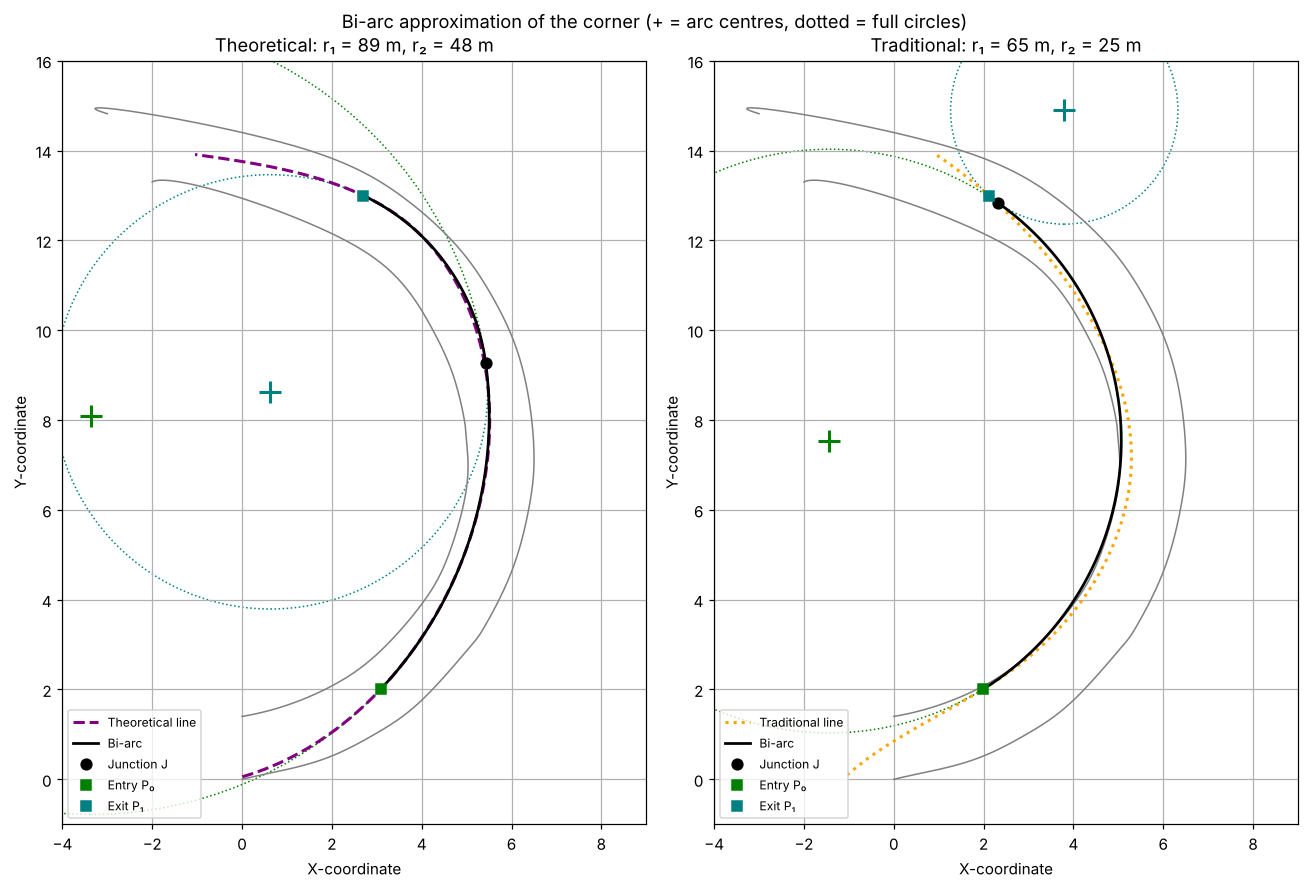

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 8))
for ax, (name, B) in zip(axes, biarcs.items()):
    for edge in ["Inner", "Outer"]:
        _, ex, ey = sample(edge)
        ax.plot(ex, ey, color="grey", lw=1)
    _, _, _, x, y = profiles[name]
    ax.plot(x, y, color=style[name]["color"], ls=style[name]["ls"], lw=2, label=f"{name} line")
    ax.plot(B["pts"][:, 0], B["pts"][:, 1], color="black", lw=1.8, label="Bi-arc")
    for c, col, r in [(B["c1"], "green", B["r1"]), (B["c2"], "teal", B["r2"])]:
        ax.plot(*c, marker="+", color=col, ms=14, mew=2)
        ax.add_patch(plt.Circle(c, r, fill=False, color=col, ls=":", lw=1))
    ax.plot(*B["J"], "ko", ms=7, label="Junction J")
    ax.plot(*B["P0"], "gs", ms=6, label="Entry P₀")
    ax.plot(*B["P1"], "s", color="teal", ms=6, label="Exit P₁")
    ax.set_title(f"{name}: r₁ = {B['r1'] * METERS_PER_UNIT:.0f} m, r₂ = {B['r2'] * METERS_PER_UNIT:.0f} m")
    ax.set_xlim(-4, 9); ax.set_ylim(-1, 16)
    ax.set_aspect("equal"); ax.grid(True); ax.legend(loc="lower left", fontsize=8)
    ax.set_xlabel("X-coordinate"); ax.set_ylabel("Y-coordinate")
plt.suptitle("Bi-arc approximation of the corner (+ = arc centres, dotted = full circles)")
plt.tight_layout()
plt.show()

In [10]:
rows = []
for name, B in biarcs.items():
    u1, u2 = B["J"] - B["c1"], B["J"] - B["c2"]
    # tangent continuity at J: both radius vectors to J must be parallel
    angle = np.degrees(np.arccos(np.clip(abs(u1 @ u2) / (np.linalg.norm(u1) * np.linalg.norm(u2)), -1, 1)))
    r1, r2 = B["r1"] * METERS_PER_UNIT, B["r2"] * METERS_PER_UNIT
    _, _, k, _, _ = profiles[name]
    rows.append({
        "line": name,
        "spline min radius (m)": METERS_PER_UNIT / k.max(),
        "bi-arc r1 (m)": r1,
        "bi-arc r2 (m)": r2,
        "v_max arc 1 (km/h)": np.sqrt(A_LAT_MAX * r1) * 3.6,
        "v_max arc 2 (km/h)": np.sqrt(A_LAT_MAX * r2) * 3.6,
        "tangent mismatch at J (deg)": angle,
        "curvature jump at J (1/m)": abs(1 / r1 - 1 / r2),
        "max gap line vs bi-arc (m)": B["gap"] * METERS_PER_UNIT,
    })
pd.DataFrame(rows).set_index("line").round(3).T

line,Theoretical,Traditional
spline min radius (m),40.493,45.966
bi-arc r1 (m),88.744,64.982
bi-arc r2 (m),48.352,25.312
v_max arc 1 (km/h),212.440,181.788
v_max arc 2 (km/h),156.811,113.457
tangent mismatch at J (deg),0.000,0.000
curvature jump at J (1/m),0.009,0.024
max gap line vs bi-arc (m),0.800,2.874


**Reading the table:**

* *Tangent mismatch at J* is about 0°, so the two arcs join smoothly in direction (G¹ continuity).
* *Curvature jump at J* is not zero: the radius changes suddenly from $r_1$ to $r_2$. In real driving this would mean the lateral acceleration $v^2/r$ jumps instantly, which a car cannot do. This is a limitation of the bi-arc model compared with the spline, where curvature changes continuously.
* *Max gap* shows how far the bi-arc is from the spline. A small gap means two circles are a good approximation of the line.

## 7. Time through the corner (braking and acceleration)

On the straight before the corner, the car brakes with constant deceleration $A$. Using $a = v\,\dfrac{dv}{ds}$ and separating variables:

$$\int_{v_0}^{v} v\,dv = \int_0^s A\,ds \quad\Longrightarrow\quad v^2 = v_0^2 + 2As .$$

The speed along each line is the lowest of:

* the cornering limit $\sqrt{a_{max}/\kappa}$,
* the speed from which the car can still brake in time for the next point (backward pass, $v^2 = v_{next}^2 + 2A_{brake}\,\Delta s$),
* the speed it can accelerate to from the previous point (forward pass, $v^2 = v_{prev}^2 + 2A_{acc}\,\Delta s$).

The time is then $\displaystyle T = \int \frac{ds}{v}$.

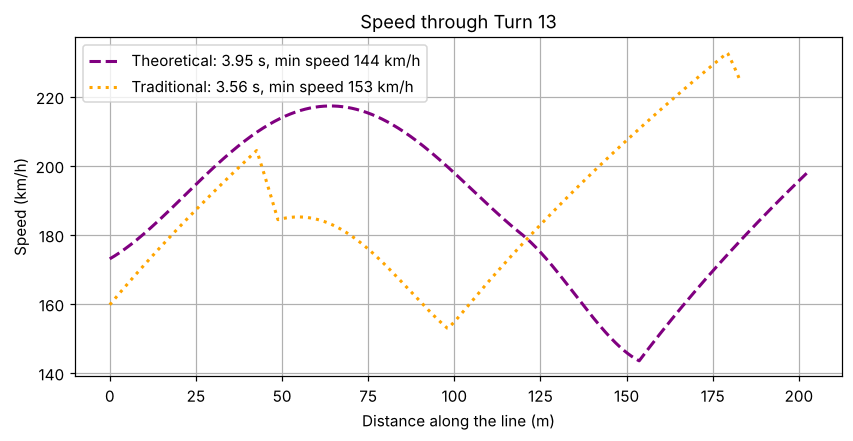

In [11]:
A_BRAKE = 5.0 * G      # assumption: maximum braking deceleration (m/s^2)
A_ACC = 1.5 * G        # assumption: maximum acceleration out of the corner (m/s^2)
V_ENTRY = 80.0         # assumption: speed at the start of the line (m/s) ≈ 288 km/h

def speed_profile(name):
    u, s, k, x, y = profiles[name]
    s_m = s * METERS_PER_UNIT
    k_m = np.maximum(k / METERS_PER_UNIT, 1e-9)
    v = np.minimum(np.sqrt(A_LAT_MAX / k_m), V_TOP)
    v[0] = min(v[0], V_ENTRY)
    ds = np.diff(s_m)
    for i in range(1, len(v)):                      # forward pass: acceleration
        v[i] = min(v[i], np.sqrt(v[i-1]**2 + 2 * A_ACC * ds[i-1]))
    for i in range(len(v) - 2, -1, -1):             # backward pass: braking
        v[i] = min(v[i], np.sqrt(v[i+1]**2 + 2 * A_BRAKE * ds[i]))
    T = np.sum(ds / (0.5 * (v[1:] + v[:-1])))
    return s_m, v, T, x, y

speeds = {name: speed_profile(name) for name in profiles}

fig, ax = plt.subplots(figsize=(9, 4))
for name, (s_m, v, T, x, y) in speeds.items():
    ax.plot(s_m, v * 3.6, color=style[name]["color"], ls=style[name]["ls"], lw=2,
            label=f"{name}: {T:.2f} s, min speed {v.min() * 3.6:.0f} km/h")
ax.set_xlabel("Distance along the line (m)")
ax.set_ylabel("Speed (km/h)")
ax.set_title("Speed through Turn 13")
ax.grid(True)
ax.legend()
plt.show()

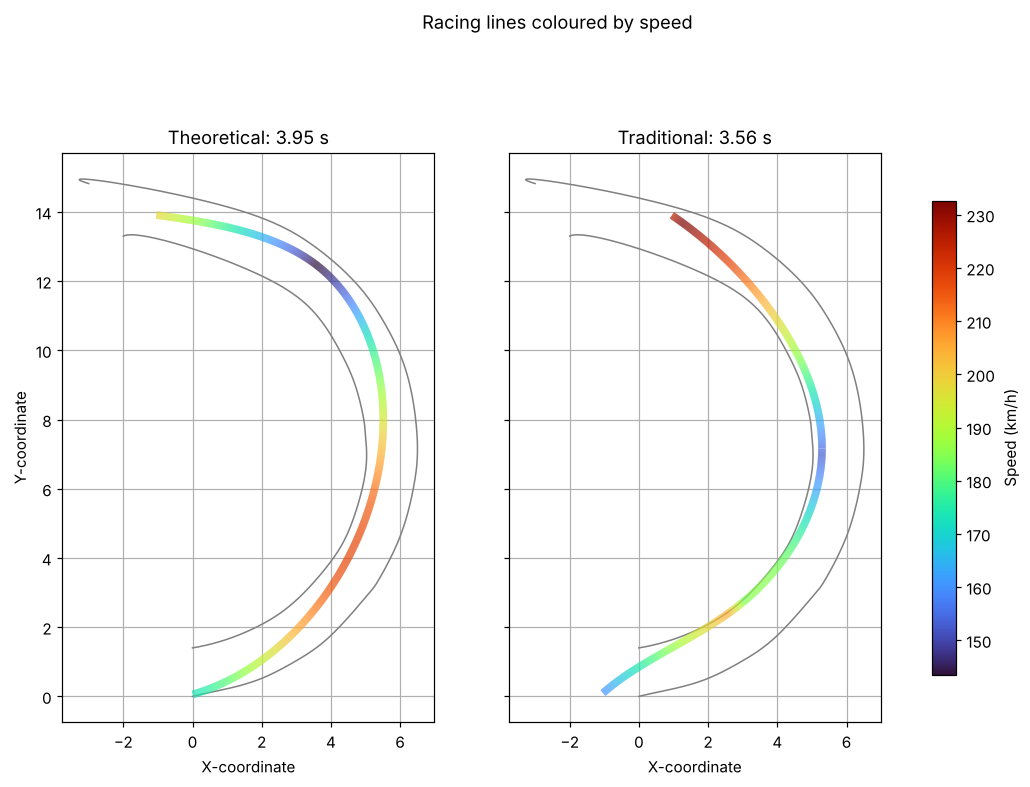

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)
vmin = min(v.min() for _, v, _, _, _ in speeds.values()) * 3.6
vmax = max(v.max() for _, v, _, _, _ in speeds.values()) * 3.6
for ax, (name, (s_m, v, T, x, y)) in zip(axes, speeds.items()):
    for edge in ["Inner", "Outer"]:
        _, ex, ey = sample(edge)
        ax.plot(ex, ey, color="grey", lw=1)
    seg = np.stack([np.column_stack([x[:-1], y[:-1]]), np.column_stack([x[1:], y[1:]])], axis=1)
    lc = LineCollection(seg, cmap="turbo", norm=plt.Normalize(vmin, vmax), lw=5)
    lc.set_array(v[:-1] * 3.6)
    ax.add_collection(lc)
    ax.set_title(f"{name}: {T:.2f} s")
    ax.set_aspect("equal"); ax.grid(True); ax.set_xlabel("X-coordinate")
axes[0].set_ylabel("Y-coordinate")
fig.colorbar(lc, ax=axes, label="Speed (km/h)", shrink=0.7)
plt.suptitle("Racing lines coloured by speed")
plt.show()

## 8. Bézier reconstruction of the racing lines

A second set of points for the theoretical and traditional lines, joined with **composite cubic Bézier curves**.
Each piece between points $P_i$ and $P_{i+1}$ is

$$B(u) = (1-u)^3 P_i + 3u(1-u)^2 C_1 + 3u^2(1-u) C_2 + u^3 P_{i+1}, \qquad 0 \le u \le 1,$$

with control points $C_1 = P_i + \tfrac{1}{6}(P_{i+1} - P_{i-1})$ and $C_2 = P_{i+1} - \tfrac{1}{6}(P_{i+2} - P_i)$ (Catmull–Rom), so the curve passes through every point with a continuous tangent.

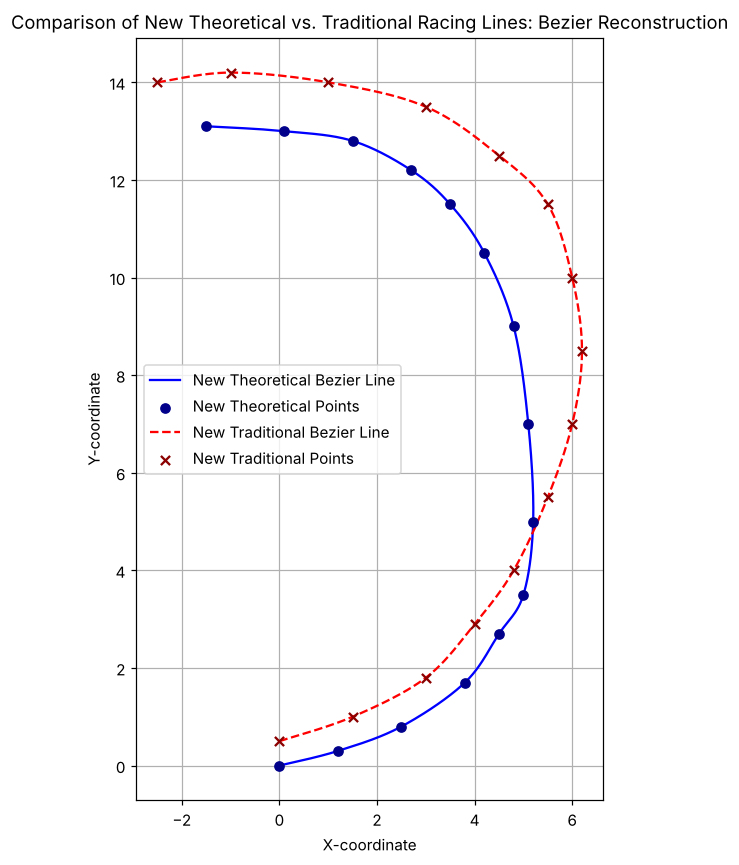

In [13]:
new_theoretical = np.array([
    (0.0, 0.0), (1.2, 0.3), (2.5, 0.8), (3.8, 1.7), (4.5, 2.7), (5.0, 3.5), (5.2, 5.0), (5.1, 7.0),
    (4.8, 9.0), (4.2, 10.5), (3.5, 11.5), (2.7, 12.2), (1.5, 12.8), (0.1, 13.0), (-1.5, 13.1),
])
new_traditional = np.array([
    (0.0, 0.5), (1.5, 1.0), (3.0, 1.8), (4.0, 2.9), (4.8, 4.0), (5.5, 5.5), (6.0, 7.0), (6.2, 8.5),
    (6.0, 10.0), (5.5, 11.5), (4.5, 12.5), (3.0, 13.5), (1.0, 14.0), (-1.0, 14.2), (-2.5, 14.0),
])

def bezier_through(P, n_per=40):
    # Composite cubic Bezier through all points (Catmull-Rom control points)
    P = np.vstack([P[0], P, P[-1]])          # repeat end points
    u = np.linspace(0, 1, n_per)[:, None]
    out = []
    for i in range(1, len(P) - 2):
        p0, p1 = P[i], P[i + 1]
        c1 = p0 + (P[i + 1] - P[i - 1]) / 6
        c2 = p1 - (P[i + 2] - P[i]) / 6
        out.append((1-u)**3 * p0 + 3*u*(1-u)**2 * c1 + 3*u**2*(1-u) * c2 + u**3 * p1)
    return np.vstack(out)

fig, ax = plt.subplots(figsize=(7, 9))
bt, br = bezier_through(new_theoretical), bezier_through(new_traditional)
ax.plot(bt[:, 0], bt[:, 1], "b-", label="New Theoretical Bezier Line")
ax.scatter(*new_theoretical.T, color="darkblue", zorder=5, label="New Theoretical Points")
ax.plot(br[:, 0], br[:, 1], "r--", label="New Traditional Bezier Line")
ax.scatter(*new_traditional.T, color="darkred", marker="x", zorder=5, label="New Traditional Points")
ax.set_title("Comparison of New Theoretical vs. Traditional Racing Lines: Bezier Reconstruction")
ax.set_xlabel("X-coordinate"); ax.set_ylabel("Y-coordinate")
ax.set_aspect("equal"); ax.grid(True); ax.legend(loc="center left")
plt.show()

## 9. Model drawn over the aerial image of Turn 13

Upload `track.png` (the aerial screenshot with the grid) to the Colab files panel, then run this cell.
The image's grid lines are 1 unit apart, so the model lines up with the photo.

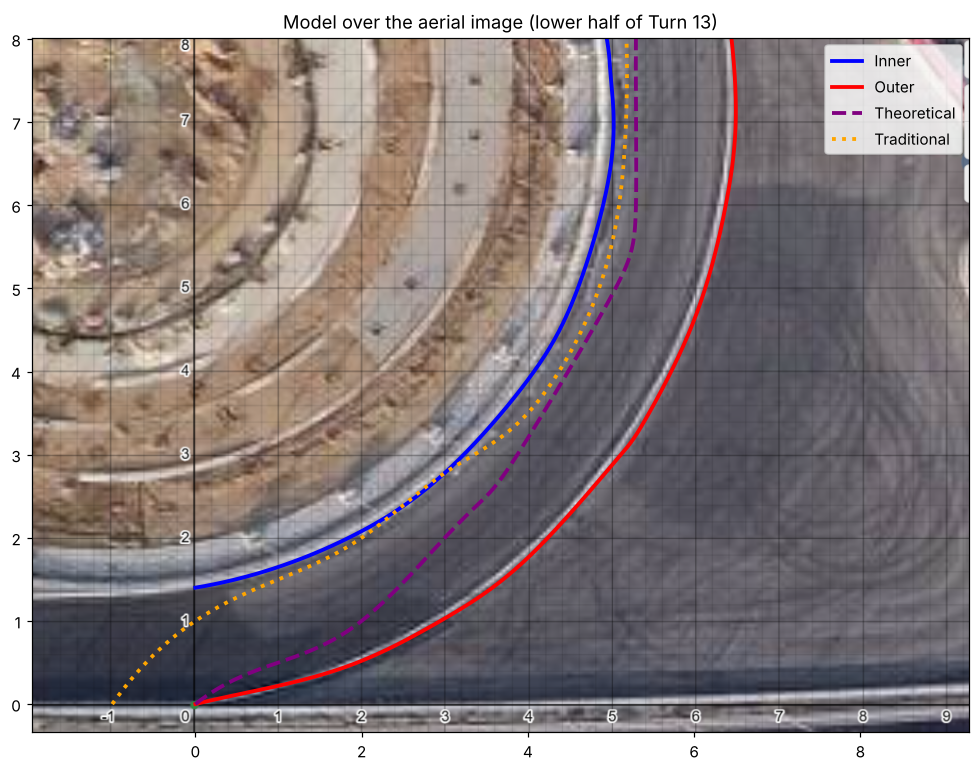

In [14]:
import os
if os.path.exists("track.png"):
    img = plt.imread("track.png")
    # extent of the screenshot in grid units (from its axis labels: 1 unit ≈ 101.5 px, origin at px (200, 816))
    extent = [-200 / 101.5, (img.shape[1] - 200) / 101.5, -(img.shape[0] - 816) / 101.8, 816 / 101.8]
    fig, ax = plt.subplots(figsize=(11, 8.2))
    ax.imshow(img, extent=extent)
    for name in lines:
        _, x, y = sample(name)
        ax.plot(x, y, color=style[name]["color"], ls=style[name]["ls"], lw=2.5, label=name)
    ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
    ax.set_title("Model over the aerial image (lower half of Turn 13)")
    ax.legend(loc="upper right")
    plt.show()
else:
    print("track.png not found - upload it to the Colab files panel to see the overlay.")

## 10. Summary

In [15]:
summary = []
for name in ["Theoretical", "Traditional"]:
    u, s, k, x, y = profiles[name]
    s_m, v, T, *_ = speeds[name]
    B = biarcs[name]
    summary.append({
        "line": name,
        "length (m)": s_m[-1],
        "min radius, spline (m)": METERS_PER_UNIT / k.max(),
        "v_max at tightest point (km/h)": np.sqrt(A_LAT_MAX * METERS_PER_UNIT / k.max()) * 3.6,
        "bi-arc radii (m)": f"{B['r1'] * METERS_PER_UNIT:.0f} / {B['r2'] * METERS_PER_UNIT:.0f}",
        "minimum speed (km/h)": v.min() * 3.6,
        "time through corner (s)": T,
    })
pd.DataFrame(summary).set_index("line").round(2)

,length (m),"min radius, spline (m)",v_max at tightest point (km/h),bi-arc radii (m),minimum speed (km/h),time through corner (s)
line,,,,,,
Theoretical,202.44,40.49,143.50,89 / 48,143.50,3.95
Traditional,182.91,45.97,152.89,65 / 25,152.89,3.56


**Strengths and limitations of each model**

* **Parametric cubic splines** follow the chosen points and give continuous curvature, so the lateral acceleration changes smoothly. But curvature uses second derivatives, so it is very sensitive to small errors in the points: with the point number as the parameter it shows large false spikes. Reparametrising by distance and allowing a little smoothing fixes this, but the result still depends on which points are picked.
* **Bi-arcs** are simple to analyse with circle geometry (each arc has one radius, so one speed limit), and they join with a continuous tangent. But the curvature jumps where the arcs meet, which is not physically realistic.
* **The speed model** depends on the assumed scale and grip values (`METERS_PER_UNIT`, `A_LAT_MAX`, `A_BRAKE`, `A_ACC`), so the absolute speeds are estimates. The comparison between the lines is more reliable than the exact numbers. Banking, downforce changing with speed, and tyre load are not included.